In [ ]:
# Nạp các thư viện dùng để xử lý dữ liệu dạng bảng, tính toán và trực quan hóa.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data

In [ ]:
# Đọc dữ liệu khách hàng từ CSV, in số dòng/cột và xem thử ba bản ghi đầu tiên.
dataset = pd.read_csv('customer_churn_dataset-training-master1.csv')

print(f"Kích thước dữ liệu gốc: {dataset.shape[0]} dòng (ngày), {dataset.shape[1]} cột (bang)")
dataset.head(3)

Kích thước dữ liệu gốc: 7043 dòng (ngày), 21 cột (bang)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [ ]:
# Xem số dòng, tên cột, kiểu dữ liệu và tình trạng giá trị thiếu của từng cột.
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
# Tính các thống kê mô tả như trung bình, độ lệch chuẩn, các tứ phân vị và giá trị cực trị.

dataset.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


- CustomerID: Mã định danh duy nhất cho mỗi khách hàng.
- Age: Tuổi của khách hàng.
- Gender: Giới tính của khách hàng (Nam hoặc Nữ).
- Tenure: Số tháng khách hàng đã sử dụng dịch vụ.
- Usage Frequency: Tần suất sử dụng dịch vụ của khách hàng.
- Support Calls: Số cuộc gọi mà khách hàng đã thực hiện tới bộ phận hỗ trợ.
- Payment Delay: Số lần thanh toán bị chậm (tính bằng ngày).
- Subscription Type: Loại gói đăng ký của khách hàng (ví dụ: Cơ bản, Tiêu chuẩn).
- Contract Length: Thời hạn hợp đồng (ví dụ: Hàng tháng, Hàng quý, Hàng năm).
- Total Spend: Tổng số tiền mà khách hàng đã chi tiêu.
- Last Interaction: Số ngày từ lần tương tác gần nhất với công ty.
- Churn: Giá trị nhị phân cho biết khách hàng có rời bỏ dịch vụ hay không (1: rời bỏ, 0: tiếp tục sử dụng dịch vụ).

# Clean data

## Kiểm tra dữ liệu bị thiếu

In [6]:
# Đếm số giá trị thiếu trong từng cột để đánh giá chất lượng dữ liệu.

dataset.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
# Loại bỏ các dòng có giá trị thiếu trực tiếp khỏi DataFrame dataset.

dataset.dropna(inplace=True)

In [8]:
# Kiểm tra lại số giá trị thiếu sau bước làm sạch dữ liệu.

dataset.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Giá trị trùng lập

In [9]:
# Đếm số dòng bị trùng hoàn toàn để kiểm tra dữ liệu lặp.

dataset.duplicated().sum()

np.int64(0)

# Visualize data

## 1. Phân tích phân phối các biến

C:\Users\ASUS\AppData\Local\Temp\ipykernel_10072\1956891091.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=churn_counts.index, y=churn_counts.values, palette='viridis')


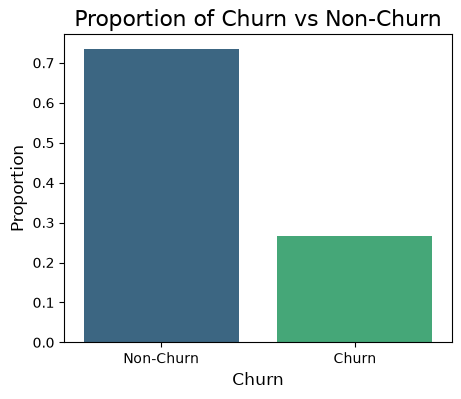

In [10]:
# Tính tỷ lệ khách hàng rời bỏ/tiếp tục sử dụng và vẽ biểu đồ cột so sánh.

# Checking churn proportions
plt.figure(figsize=(5,4))
churn_counts = dataset['Churn'].value_counts(normalize=True)
sns.barplot(x=churn_counts.index, y=churn_counts.values, palette='viridis')
plt.title('Proportion of Churn vs Non-Churn', fontsize=16)
plt.xlabel('Churn', fontsize=12)
plt.ylabel('Proportion', fontsize=12)
plt.xticks([0, 1], ['Non-Churn', 'Churn'])
plt.show()

Tỷ lệ Churn (Proportion of Churn)[customer_churn_dataset-testing-master2]:
- Churn = 1 (Rời bỏ): Chiếm tỷ lệ cao hơn (khoảng 55%).
- Churn = 0 (Không rời bỏ): Chiếm khoảng 45%.

Kết luận: Số lượng khách hàng rời bỏ dịch vụ (55%) cao hơn số lượng khách hàng tiếp tục sử dụng dịch vụ (45%)

ValueError: Could not interpret value `Gender` for `x`. An entry with this name does not appear in `data`.

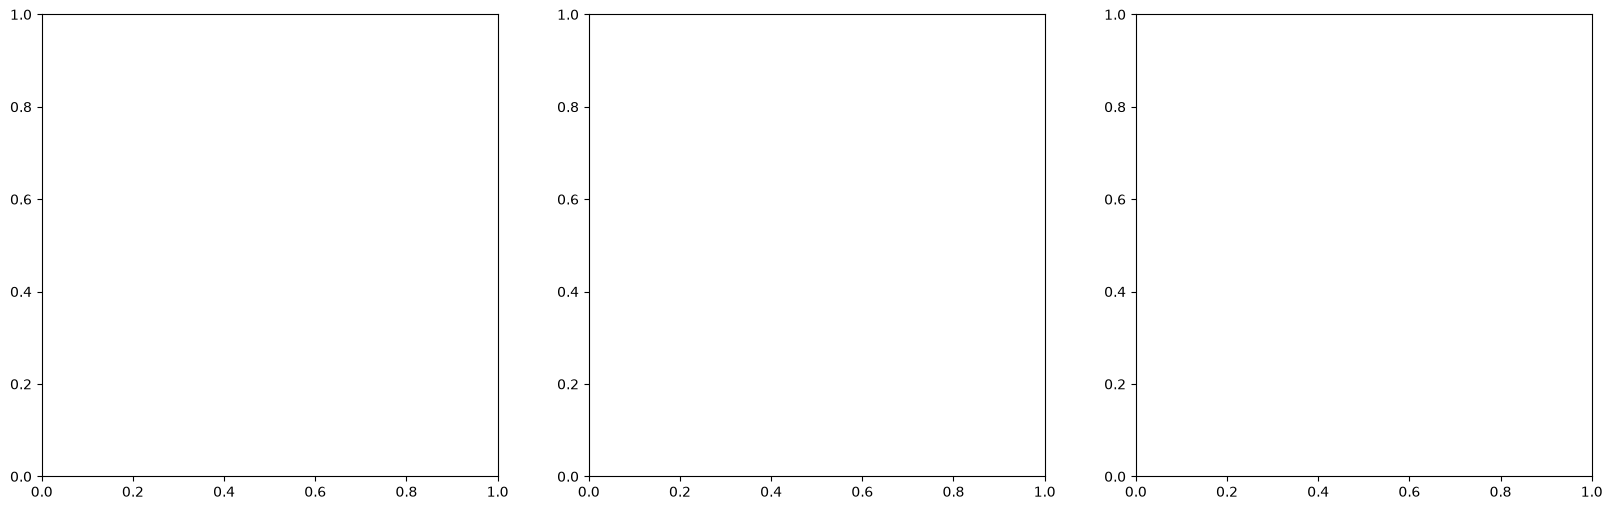

In [11]:
# Vẽ biểu đồ số lượng cho từng nhóm của các biến phân loại.

categorical_cols = ['Gender', 'Subscription Type', 'Contract Length']

# Plotting distribution (frequency counts) for categorical variables
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot bar plots for each categorical variable
for i, col in enumerate(categorical_cols):
    sns.countplot(x=col, data=dataset, palette='viridis', ax=axes[i])
    axes[i].set_title(f'Distribution of {col}', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Count', fontsize=12)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Các feautures phân loại (Categorical feautures):

1. Gender (Giới tính): Số lượng khách hàng nam (Male) chiếm tỷ lệ lớn hơn nữ khách hàng (Female).

2. Subscription Type (Loại gói dịch vụ): Số lượng khách hàng ở ba gói dịch vụ Basic, Standard, và Premium gần như tương đương, gói Basic thấp hơn một xíu so với 2 loại còn lại

3. Contract Length (Thời hạn hợp đồng): Loại hợp đồng dài hạn (Hàng năm - Annual, Hàng quý - Quarterly) phổ biến hơn hẳn so với hợp đồng ngắn hạn (Hàng tháng - Monthly)


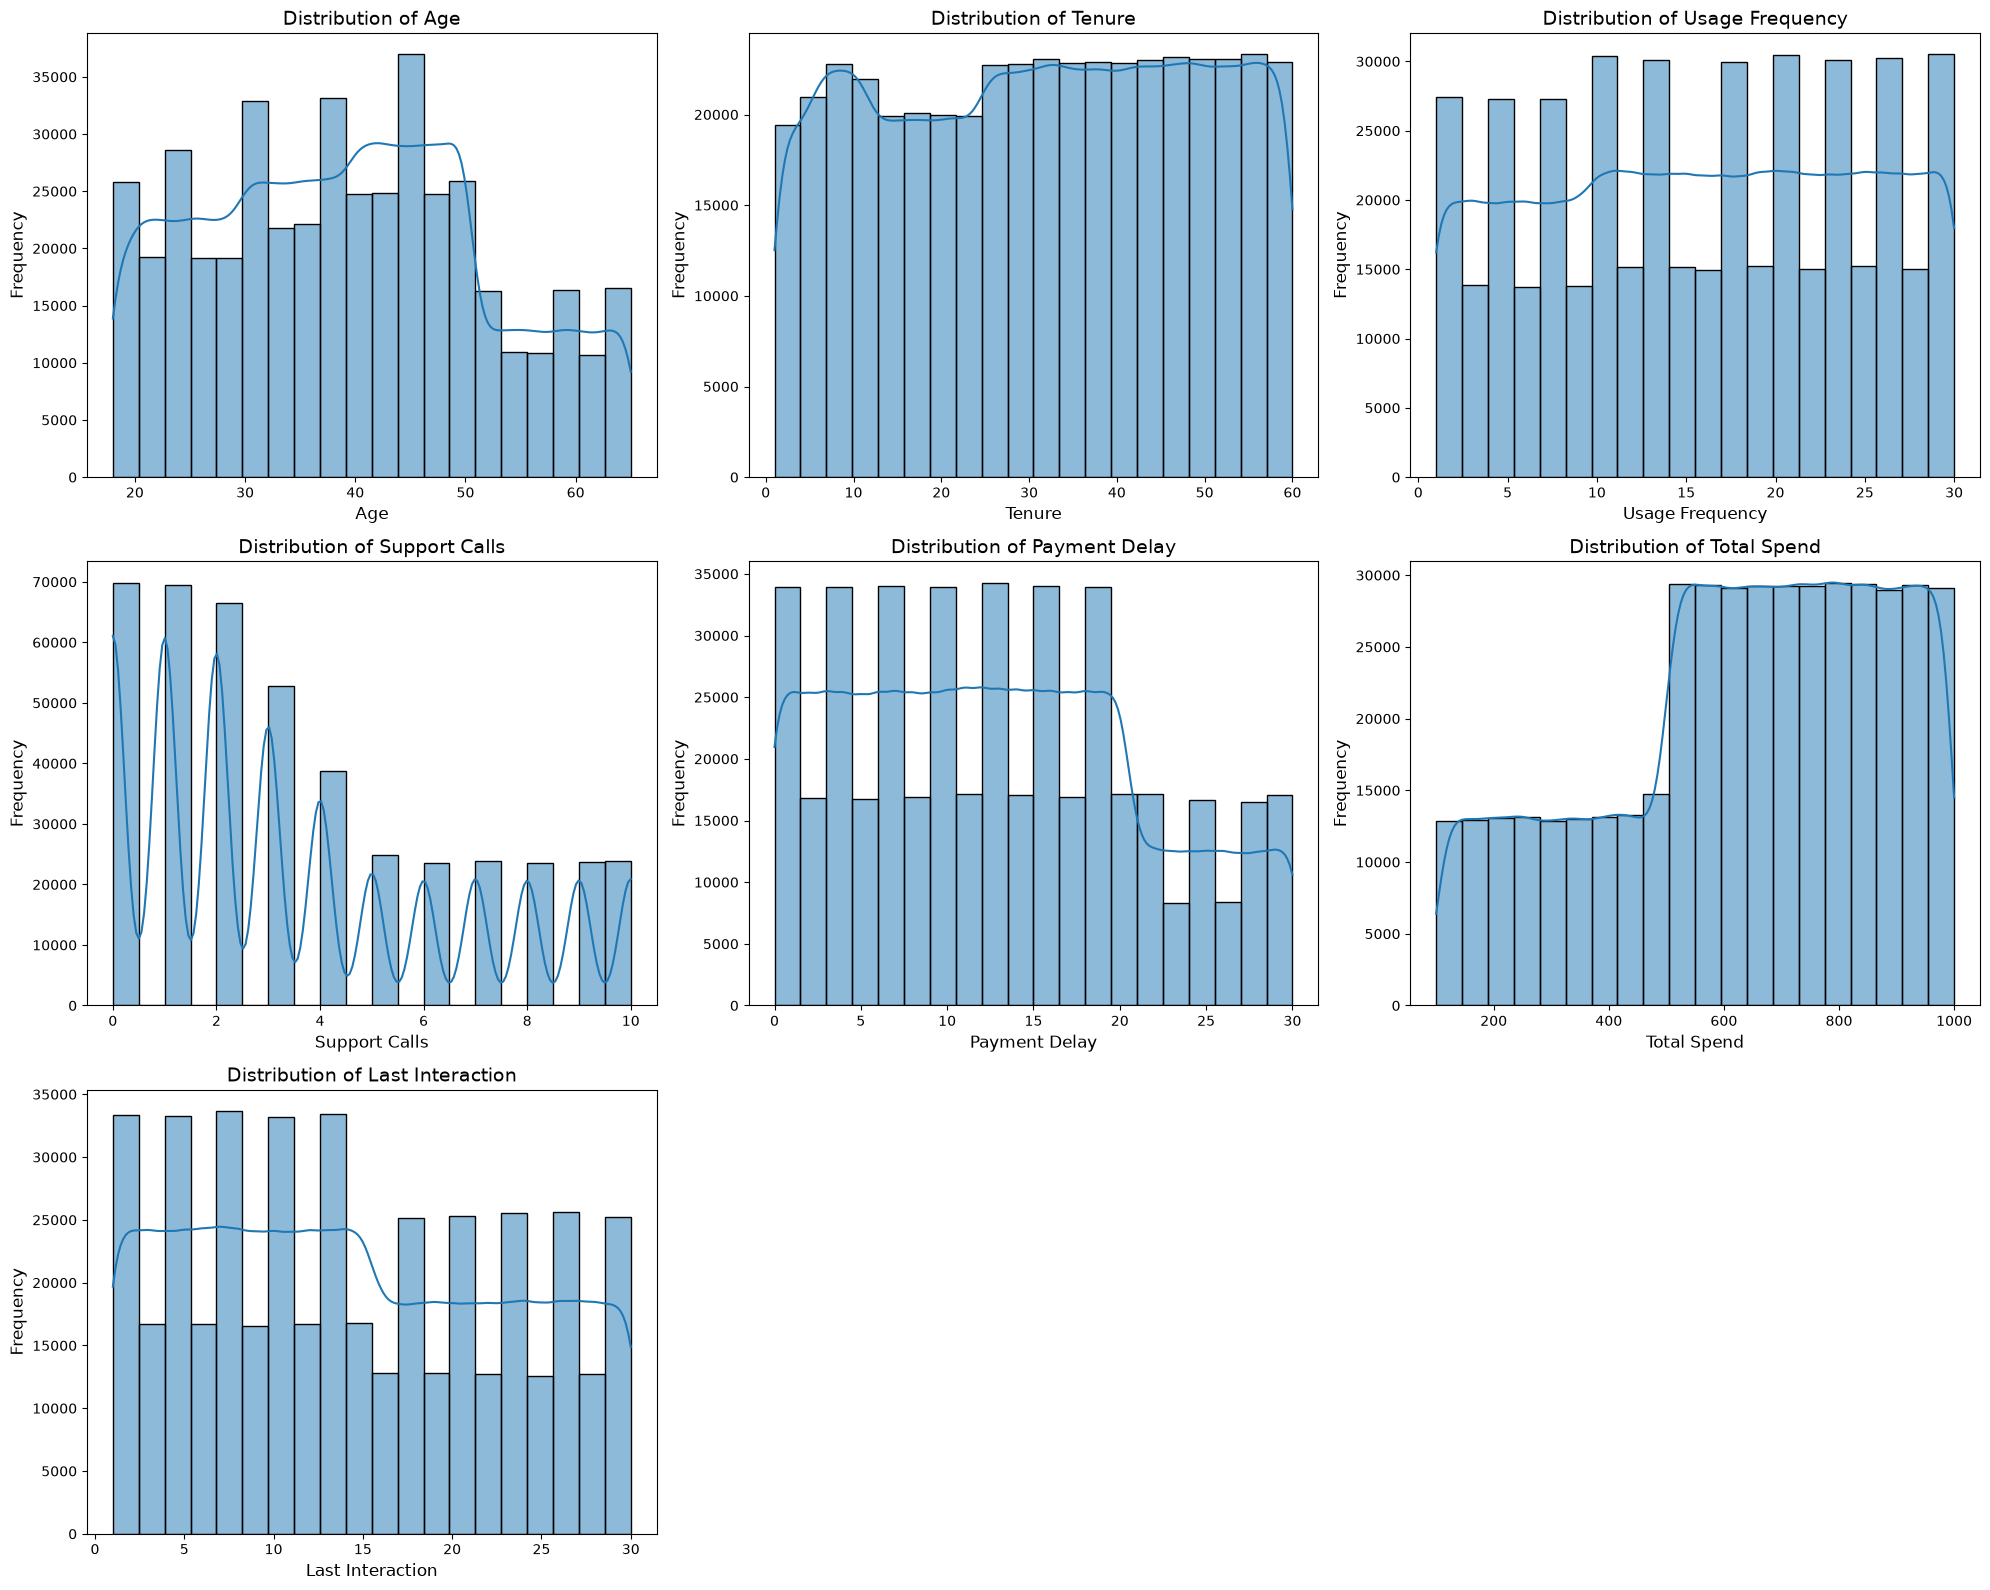

In [ ]:
# Vẽ histogram và đường mật độ để quan sát phân phối của các biến số.

numerical_cols = ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']

# Plot histograms for numerical variables
fig, axes = plt.subplots(3, 3, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(dataset[col], kde=True, bins=20, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Frequency', fontsize=12)

# Remove empty subplot
fig.delaxes(axes[-1])
fig.delaxes(axes[-2])

plt.tight_layout()
plt.show()

Các biến số (Numerical Variables):
1. Age (Tuổi): Dữ liệu được phân bổ khá đều, với một số đỉnh ở nhóm tuổi từ 30-50 và giảm mạnh ở nhóm tuổi trên 60.

2. Tenure (Thời gian sử dụng): Thời gian sử dụng dịch vụ trải rộng đều từ 0 đến 60 tháng. Số lượng khách hàng sử dụng trên 30 tháng nhiều

3. Usage Frequency (Tần suất sử dụng): Tần suất sử dụng tập trung vào mức trung bình, cho thấy phần lớn khách hàng duy trì mức độ sử dụng ổn định.

4. Support Calls (Số lần gọi hỗ trợ): Số lượng gọi hỗ trợ giảm dần từ 0 đến 10 lần. Phần lớn khách hàng gọi hỗ trợ rất ít, đa số khách hàng gọi dưới 3 lần, nhưng cũng có vài trường hợp gọi rất nhiều lần

5. Payment Delay (Trễ hạn thanh toán): Phần lớn khách hàng chậm thanh toán ở mức thấp (khoảng 0 đến trước 20 ngày), nhưng một phần nhỏ chậm thanh toán đáng kể (hơn 20 ngày) có thể là tín hiệu của khách hàng gặp vấn đề tài chính và dễ rời bỏ.

6. Total Spend (Tổng chi tiêu): Tổng chi tiêu có xu hướng tăng từ 0 - 1000 đơn vị, tăng mạnh trong khoảng (450, 550). Phần lớn khách hàng đều chi tiêu ở mức cao (> 550)

7. Last Interaction (Thời gian tương tác cuối cùng): Phần lớn khách hàng có sự tương tác gần đây ở mức trung bình (~14 ngày), nhưng một số khách hàng không nhỏ không tương tác với hệ thống trong thời gian dài (> 16,17 ngày)

## 2. Phân tích mối quan hệ giữa các biến và `Churn`

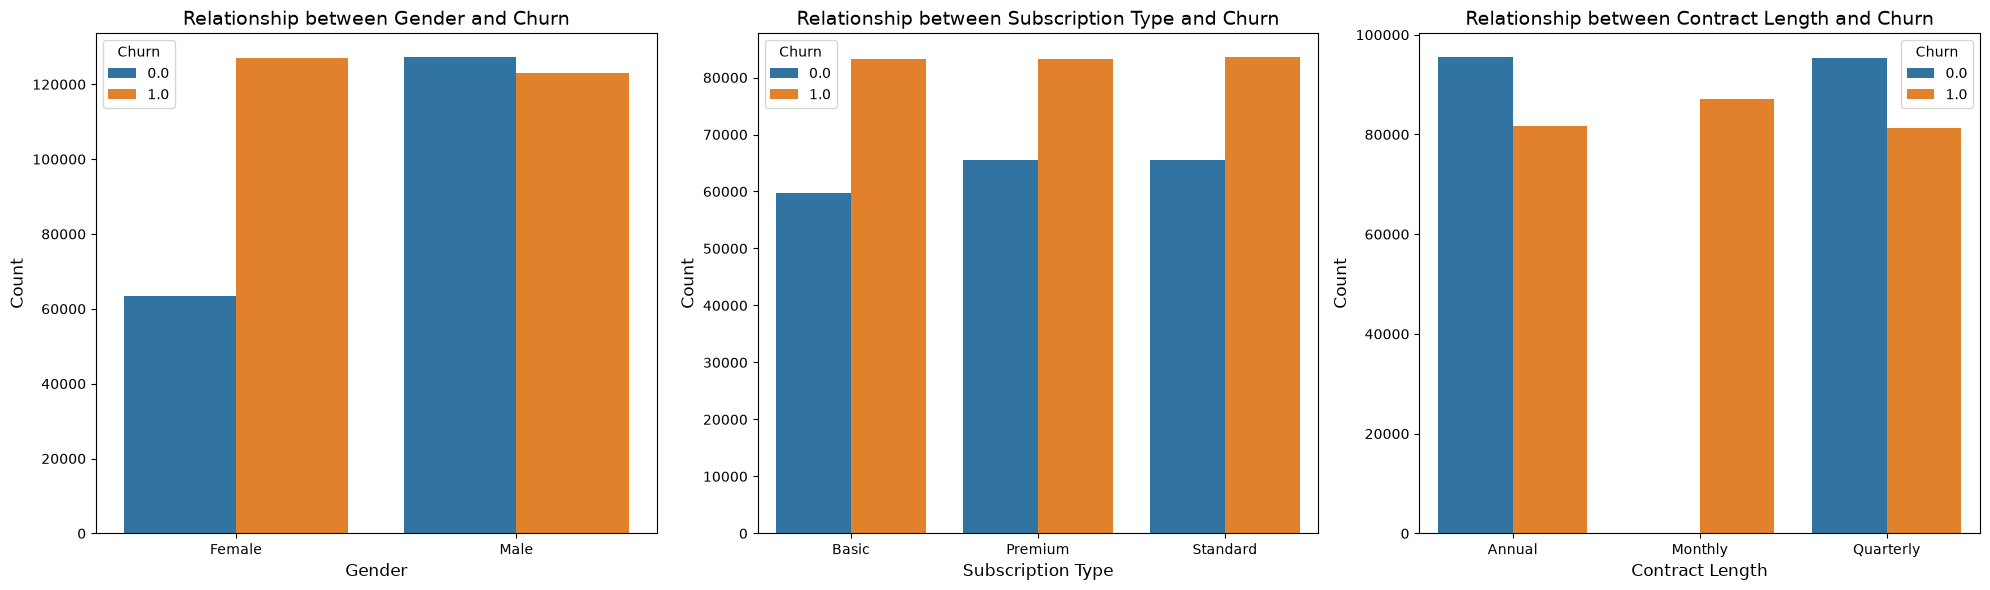

In [ ]:
# So sánh số lượng khách hàng rời bỏ và ở lại theo từng biến phân loại.

# Create subplots for categorical variables and their relationship with 'Churn'
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 6))

for i, col in enumerate(categorical_cols):
    churn_counts = dataset.groupby([col, 'Churn']).size().reset_index(name='Count')
    sns.barplot(x=col, y='Count', hue='Churn', data=churn_counts, ax=axes[i])
    axes[i].set_title(f'Relationship between {col} and Churn', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Count', fontsize=12)
    axes[i].legend(title='Churn')

plt.tight_layout()
plt.show()

Đặc trưng phân loại (Categorical features):

1. Gender (Giới tính): Có sự khác biệt rõ rệt giữa 2 giới tính:
- Số lượng khách hàng nam rời đi ít hơn so với khách hàng nữ
- Đối với khách hàng nam, số lượng khách hàng tiếp tục ở lại sử dụng dịch vụ (`churn=0`) cao hơn số lượng rời đi
- Ngược lại, đối với khách hàng nữ, số lượng khách hàng rời đi khoảng gấp đôi so với số lượng ở lại

2. Subscription Type (Loại gói dịch vụ):
- Gói "Basic" có tỷ lệ churn cao hơn so với "Standard" và "Premium" -> Gói cao cấp hơn giữ chân khách hàng tốt hơn.

3. Contract Length (Thời hạn hợp đồng):
- Hợp đồng "Monthly" có tỷ lệ churn cao hơn đáng kể so với "Annual" và "Quarterly". Cụ thể, hầu hết khách hàng sử dụng gói "Monthly" sẽ không tiếp tục sử dụng dịch vụ. Trong khi đó, hợp đồng dài hạn giúp giữ chân khách hàng hiệu quả hơn.

Kết luận: Nên có các chiến lược kinh doanh dịch vụ tập trung vào khách hàng Nữ nhiều hơn, đồng thời, cũng nên có các chiến lược cải thiện giá trị gói Basic và loại hợp đồng Monthly

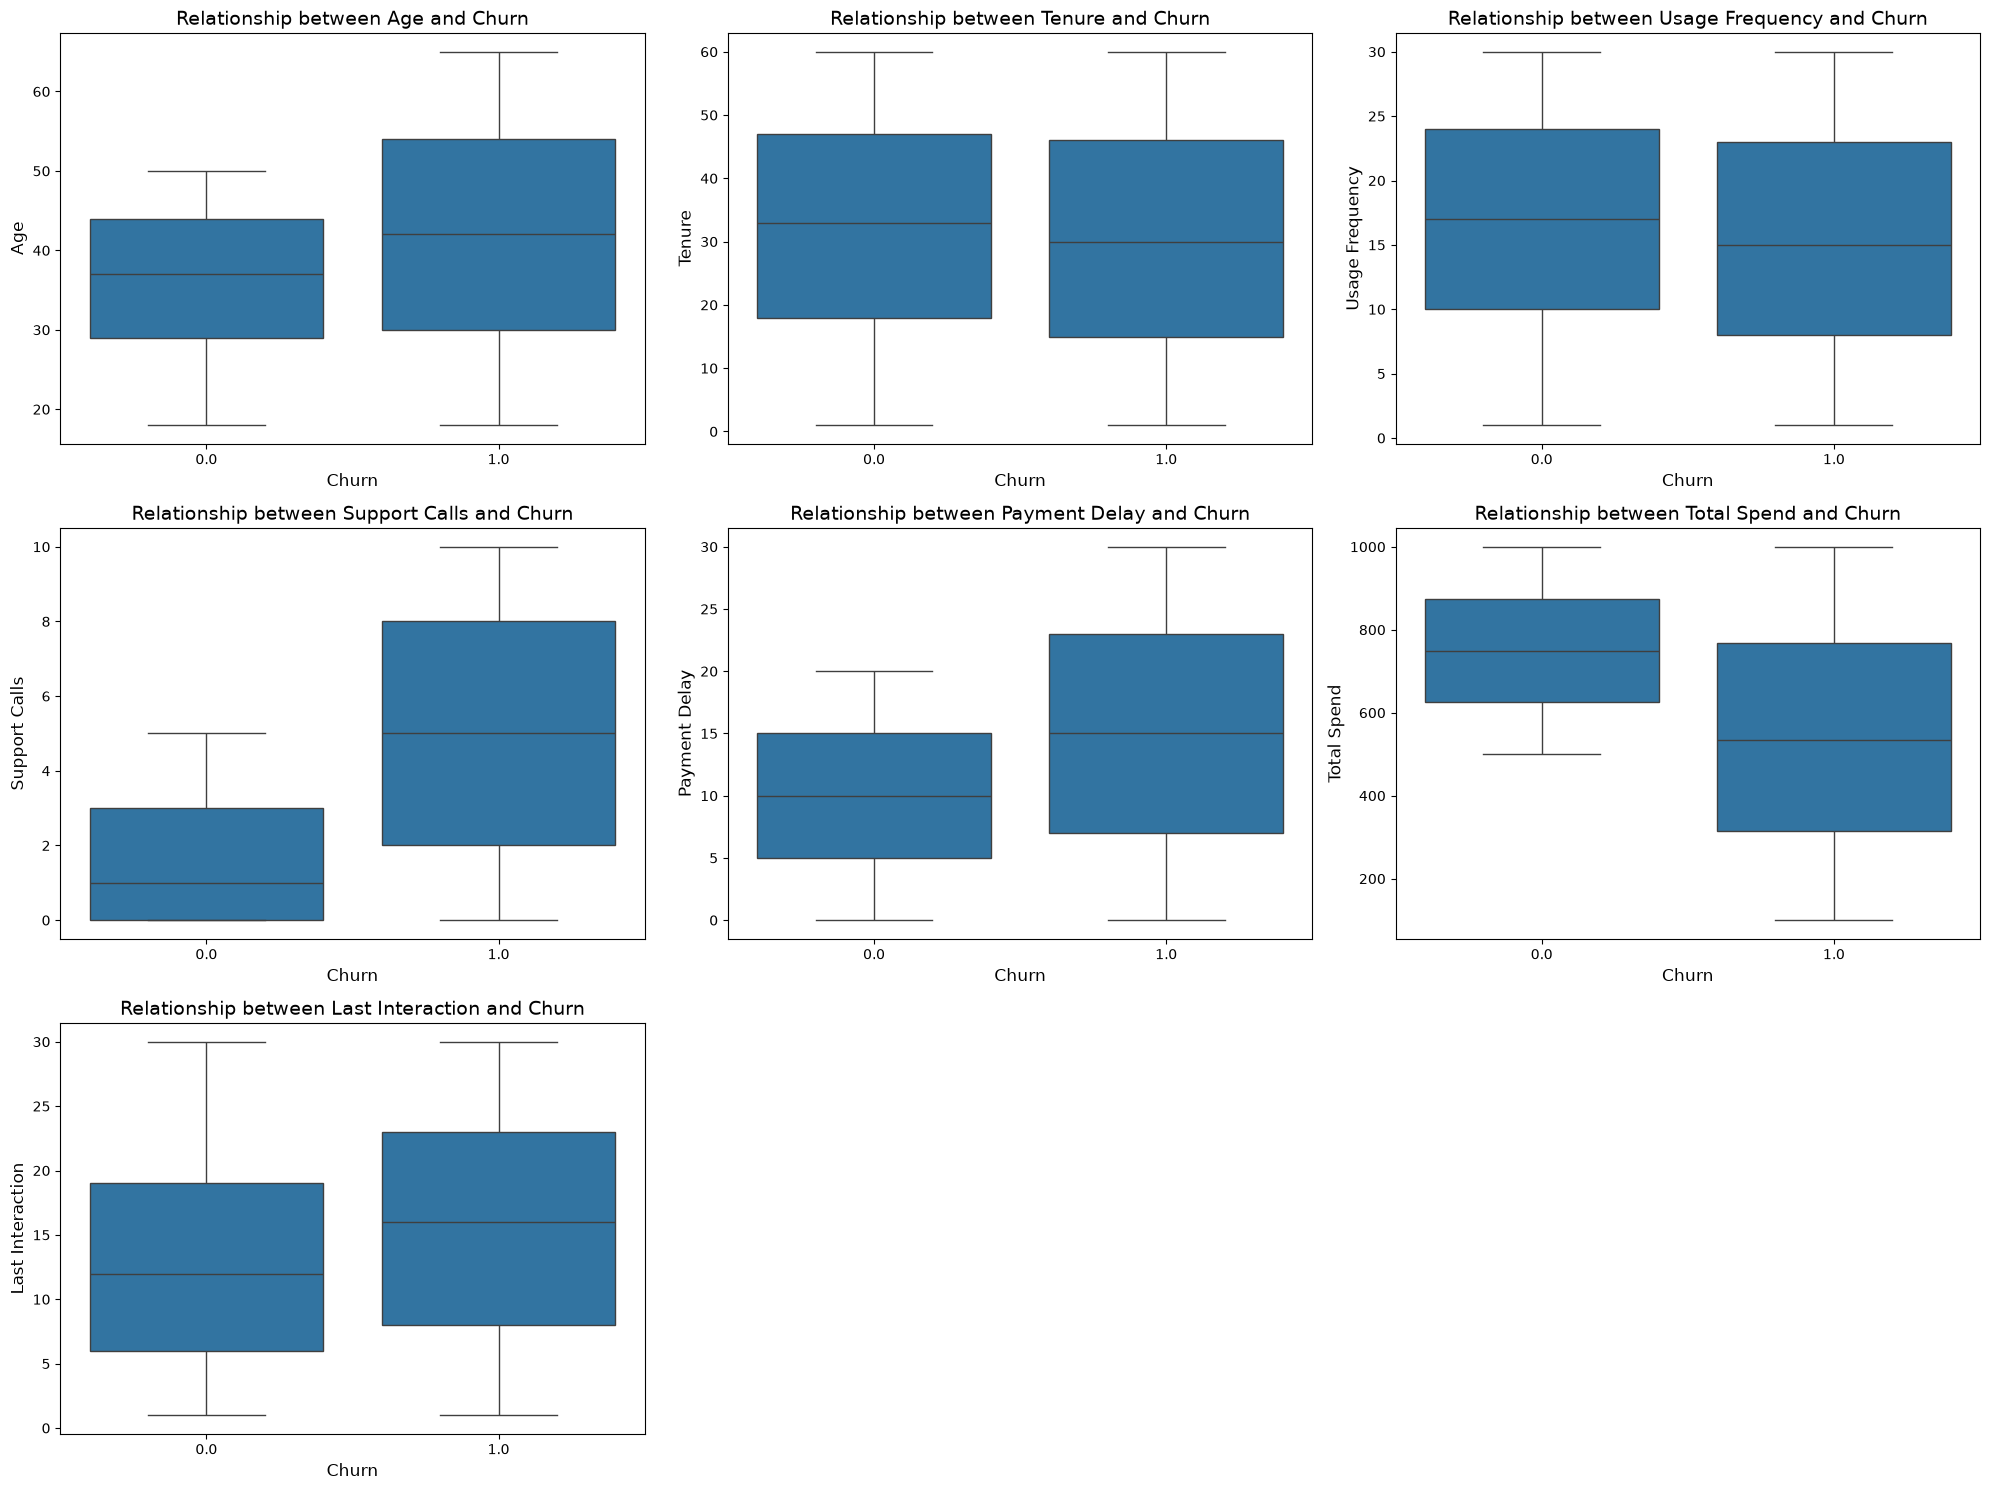

In [ ]:
# Dùng boxplot để so sánh phân phối các biến số giữa hai nhóm Churn.

# Create subplots for numerical variables and their relationship with 'Churn'
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(20, 15))
axes = axes.flatten()

numerical_cols = ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 
                  'Payment Delay', 'Total Spend', 'Last Interaction']

for i, col in enumerate(numerical_cols):
    sns.boxplot(x='Churn', y=col, data=dataset, ax=axes[i])
    axes[i].set_title(f'Relationship between {col} and Churn', fontsize=14)
    axes[i].set_xlabel('Churn', fontsize=12)
    axes[i].set_ylabel(col, fontsize=12)

# Remove empty subplots if any
for j in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Biến số (Numerical Variables):

1. Age (Tuổi):
- Trung vị (median):
    - Nhóm Non-Churn (Churn=0): Trung vị nằm khoảng 40 tuổi.
    - Nhóm Churn (Churn=1): Trung vị cao hơn, nằm khoảng 45 tuổi.
- Phạm vi phân phối (IQR - Interquartile Range):
    - Nhóm Non-Churn: Phân phối tập trung chủ yếu từ 30 đến 50 tuổi.
    - Nhóm Churn: Phân phối rộng hơn, trải dài từ 20 đến 60 tuổi.
- Kết luận:
    - Nhóm Churn có phân phối rộng hơn về độ tuổi: Khách hàng lớn tuổi hơn (45+) và khách hàng trẻ tuổi hơn (30-) sẽ có xu hướng Churn
    - Age không phải là yếu tố quyết định duy nhất trong việc khách hàng có rời bỏ hay không, phải kết hợp với các yếu tố khác

2. Tenure (Thời gian sử dụng):
- Có sự tương đồng cao giữa 2 nhóm `churn=0` và `churn=1`
- Giá trị trung vị (median) rất gần nhau (~30 tháng),
- Phạm vi phân phối (IQR) cũng rất tương đồng nhau (~10-50 tháng)
- Kết luận: Tenure không phải là yếu tổ mạnh để phân biệt giữa 2 nhóm Churn và Non-churn

3. Usage Frequency (Tần suất sử dụng):
- Tương tự, Usage Frequency cũng không phải là yếu tố mạnh để đánh giá một khách hàng có sẽ rời đi hay tiếp tục sử dụng dịch vụ

4. Support Calls (Số lần gọi hỗ trợ):
- Nhóm Non-Churn (`churn=0`):
    - Trung vị: Số lần gọi hỗ trợ không cao, với khoảng 1-2 lần.
    - Phạm vi phân phối: Hầu hết khách hàng Non-Churn có số lần gọi hỗ trợ dưới 4 lần (IQR nằm trong khoảng 0-4).
- Nhóm Churn (`churn=1`):
    - Median (trung vị) của nhóm này cao hơn rõ rệt, nằm ở khoảng 6 lần.
    - Phạm vi phân phối rộng hơn đáng kể, với nhiều khách hàng có số lần gọi hỗ trợ lên tới 8-10 lần.
- Kết luận: Support Calls là yếu tố quan trọng ảnh hưởng đến Churn
    - Nhóm Churn có số lần gọi hỗ trợ cao hơn đáng kể so với Non-Churn.
    - Nhóm Non-Churn thường không hoặc rất ít gọi hỗ trợ, cho thấy họ hài lòng với dịch vụ và không cần yêu cầu thêm.
    - Khách hàng thường xuyên gọi hỗ trợ (trên 5 lần) có xu hướng rời bỏ dịch vụ cao hơn, có thể do không hài lòng với dịch vụ

5. Payment Delay (Trễ hạn thanh toán):
- Nhóm Churn = 0 (Non-Churn):
    - Median (Trung vị): Khoảng 10 ngày.
    - Phạm vi phân phối: Tập trung trong khoảng 5-15 ngày. Có số ít khách hàng có Payment Delay vượt 20 ngày, nhưng không đáng kể
- Nhóm Churn = 1 (Churn):
    - Median (Trung vị): Cao hơn đáng kể, nằm ở khoảng 15 ngày.
    - Phạm vi phân phối: Rộng hơn, với phần lớn khách hàng có Payment Delay nằm trong khoảng 10-20 ngày và trải dài đến 30 ngày.
- Kết luận: Payment Delay là một yếu tố quan trọng ảnh hưởng đến Churn:
    - Biểu đồ cho thấy rõ ràng nhiều khách hàng trong nhóm Churn có Payment Delay cao hơn nhóm Non-Churn, tức là khách hàng có thời gian chậm thanh toán dài (Payment Delay cao) có nguy cơ Churn cao hơn.
    - Phân phối rộng hơn của nhóm Churn (với nhiều khách hàng vượt quá 20 ngày) có thể phản ánh các vấn đề tài chính hoặc sự không hài lòng với dịch vụ.
    
6. Total Spend (Tổng chi tiêu):

- Nhóm Churn = 0 (Non-Churn):
    - Median (Trung vị): Khoảng 800.
    - Phạm vi phân phối: Tập trung trong khoảng 600-900, phản ánh mức chi tiêu cao hơn so với nhóm Churn.
    - Phân phối rất hẹp, với hầu hết khách hàng có chi tiêu cao và ổn định.
- Nhóm Churn = 1 (Churn):
    - Median (Trung vị): Khoảng 500
    - Phạm vi phân phối: Rộng hơn so với nhóm Non-Churn, nằm trong khoảng 300-700
- Kết luận: Total Spend cũng là một yếu tố quan trọng trong việc dự đoán Churn:
    - Nhóm Churn có xu hướng chi tiêu thấp hơn đáng kể so với nhóm Non-Churn.
    - Khách hàng chi tiêu ít (<600) thường có nguy cơ Churn cao
  
7. Last Interaction (Thời gian tương tác cuối cùng):
- Nhóm Churn = 0 (Non-Churn):
    - Median (Trung vị): Khoảng 10 ngày.
    - Phạm vi phân phối: Tập trung trong khoảng 5-15 ngày, với số ít khách hàng có thời gian tương tác cuối trên 20 ngày.
    - Phân phối hẹp, phản ánh rằng khách hàng Non-Churn thường có tương tác gần đây.
- Nhóm Churn = 1 (Churn):
    - Median (Trung vị): Cao hơn nhóm Non-Churn, nằm ở khoảng 15 ngày.
    - Phạm vi phân phối: Phân phối rộng hơn, nằm trong khoảng 10-20 ngày.
- Kết luận: Last Interaction cũng là 1 yếu tố ảnh hưởng đến việc khách hàng có rời đi hay không, nhưng không mạnh bằng các feature Support Calls, Payment Delay và Total Spend, nhưng mạnh hơn Tenure và Usage Frequency



## INSIGHTS:

1. Khách hàng gọi hỗ trợ nhiều thường có xu hướng rời đi, có thể do trải nghiệm dịch vụ mang lại không đủ tốt
2. Tài chính yếu: Khách hàng có nguy cơ Churn thường gặp vấn đề về tài chính (Payment Delay cao, Total Spend thấp, Monthly Contract).
3. Khách hàng là nữ thường có xu hướng rời đi nhiều hơn nam
4. Khách hàng cao tuổi (50+) và khách hàng thanh thiếu niên (30-) có xu hướng rời bỏ dịch vụ
5. Gắn bó thấp: Những khách hàng ít sử dụng dịch vụ, ít tương tác gần đây, thường dễ rời bỏ do có thể bất mãn với hỗ trợ khách hàng.

## 3. Phân tích mối tương quan giữa các biến số

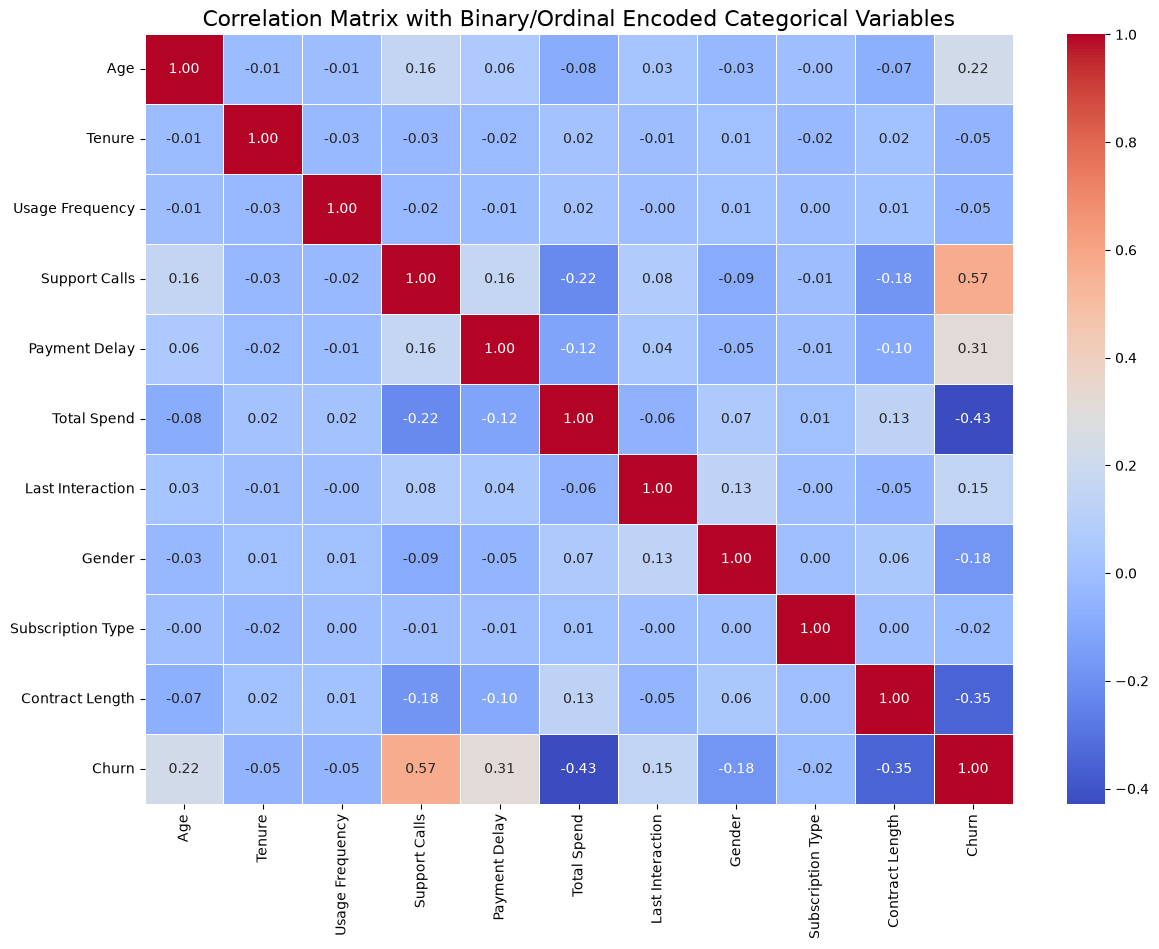

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender,Subscription Type,Contract Length,Churn
Age,1.000000,-0.011630,-0.007190,0.158451,0.061738,-0.084684,0.028980,-0.031419,-0.004414,-0.069303,0.218394
Tenure,-0.011630,1.000000,-0.026800,-0.027640,-0.016588,0.019006,-0.006903,0.007978,-0.024657,0.016925,-0.051919
Usage Frequency,-0.007190,-0.026800,1.000000,-0.022013,-0.014470,0.018631,-0.004662,0.007978,0.000032,0.014058,-0.046101
Support Calls,0.158451,-0.027640,-0.022013,1.000000,0.162889,-0.221594,0.077684,-0.091212,-0.009820,-0.178806,0.574267
Payment Delay,0.061738,-0.016588,-0.014470,0.162889,1.000000,-0.121044,0.042708,-0.048449,-0.005385,-0.098028,0.312129
Total Spend,-0.084684,0.019006,0.018631,-0.221594,-0.121044,1.000000,-0.056890,0.066138,0.007131,0.133871,-0.429355
Last Interaction,0.028980,-0.006903,-0.004662,0.077684,0.042708,-0.056890,1.000000,0.134786,-0.000608,-0.046014,0.149616
Gender,-0.031419,0.007978,0.007978,-0.091212,-0.048449,0.066138,0.134786,1.000000,0.002271,0.055342,-0.175395
Subscription Type,-0.004414,-0.024657,0.000032,-0.009820,-0.005385,0.007131,-0.000608,0.002271,1.000000,0.004850,-0.018251
Contract Length,-0.069303,0.016925,0.014058,-0.178806,-0.098028,0.133871,-0.046014,0.055342,0.004850,1.000000,-0.346666


In [ ]:
# Mã hóa một số biến phân loại thành số, sau đó tính và trực quan hóa ma trận tương quan.

# Encode Gender and other categorical variables with ordinal/binary encoding
# Gender: Male = 1, Female = 0
encoded_data_binary = dataset.copy()
encoded_data_binary['Gender'] = encoded_data_binary['Gender'].apply(lambda x: 1 if x == 'Male' else 0)

# Subscription Type: Basic = 0, Standard = 1, Premium = 2
subscription_map = {'Basic': 0, 'Standard': 1, 'Premium': 2}
encoded_data_binary['Subscription Type'] = encoded_data_binary['Subscription Type'].map(subscription_map)

# Contract Length: Monthly = 0, Quarterly = 1, Annual = 2
contract_map = {'Monthly': 0, 'Quarterly': 1, 'Annual': 2}
encoded_data_binary['Contract Length'] = encoded_data_binary['Contract Length'].map(contract_map)

# Combine numerical and newly encoded categorical columns
all_columns_binary = numerical_cols + ['Gender', 'Subscription Type', 'Contract Length', 'Churn']

# Compute the correlation matrix
correlation_matrix_binary = encoded_data_binary[all_columns_binary].corr()

# Plot the heatmap for correlations
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix_binary, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix with Binary/Ordinal Encoded Categorical Variables", fontsize=16)
plt.show()

# Return the correlation matrix for review
correlation_matrix_binary

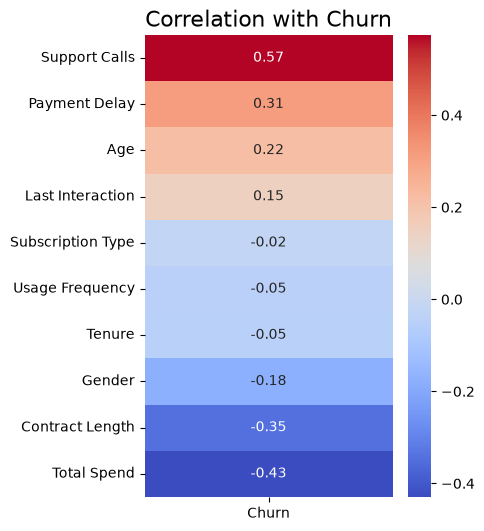

Support Calls        0.574267
Payment Delay        0.312129
Age                  0.218394
Last Interaction     0.149616
Subscription Type   -0.018251
Usage Frequency     -0.046101
Tenure              -0.051919
Gender              -0.175395
Contract Length     -0.346666
Total Spend         -0.429355
Name: Churn, dtype: float64

In [ ]:
# Sắp xếp tương quan của các biến với Churn và vẽ heatmap để dễ đối chiếu.

# Calculate correlation of all variables with the target (Churn)
target_corr = correlation_matrix_binary['Churn'].drop('Churn').sort_values(ascending=False)

# Plot the correlation of each variable with Churn
plt.figure(figsize=(4, 6))
sns.heatmap(target_corr.to_frame(), annot=True, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title("Correlation with Churn", fontsize=16)
plt.show()

# Display the correlations for reference
target_corr

# Model

1. Mục tiêu: Xây dựng 1 mô hình học máy để dự đoán khách hàng sẽ rời đi hay tiếp tục ở lại sử dụng dịch vụ từ các thông tin đã cho
- Input: Giá trị của tất cả các field trong dataset, trừ cột `churn` là target dự đoán.
- Output: Giá trị `churn`:
    - `churn=0`: Khách hàng tiếp tục ở lại
    - `churn=1`: Khách hàng rời đi, không sử dụng dịch vụ nữa

2. Model: Một số mô hình học máy phù hợp với bài toán Classification
- Logistic Regression:
- SVM:
- kNN:
- Decision Tree:
- Random Forest:

3. Lưu ý: 
- Đối với các cột có kiểu dữ liệu thuộc loại Categorical như `Gender`, `Subscription Type`, `Contract Length`: Phải tiền xử lý chúng thành các giá trị Numerical để có thể đưa vào được model
- Dữ liệu không bị mất cân bằng (~ 45% `churn=0` và ~ 55% `churn=1`) -> Không cần thiết phải cân bằng dữ liệu bằng các kỹ thuật như SMOTE, Undersampling.

## 1. Chuẩn hoá dữ liệu dạng Categorical thành dạng Numerical

In [ ]:
# Tạo bản sao dữ liệu và mã hóa các biến phân loại để chuẩn bị cho phân tích/mô hình.

# Encode categorical variables to numeric values
encoded_dataset = dataset.copy()
encoded_dataset['Gender'] = encoded_dataset['Gender'].apply(lambda x: 1 if x == 'Male' else 0)

subscription_map = {'Basic': 0, 'Standard': 1, 'Premium': 2}
encoded_dataset['Subscription Type'] = encoded_dataset['Subscription Type'].map(subscription_map)

contract_map = {'Monthly': 0, 'Quarterly': 1, 'Annual': 2}
encoded_dataset['Contract Length'] = encoded_dataset['Contract Length'].map(contract_map)

In [ ]:
# Hiển thị dữ liệu sau khi các biến phân loại đã được mã hóa.

encoded_dataset

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,0,39.0,14.0,5.0,18.0,1,2,932.00,17.0,1.0
1,3.0,65.0,0,49.0,1.0,10.0,8.0,0,0,557.00,6.0,1.0
2,4.0,55.0,0,14.0,4.0,6.0,18.0,0,1,185.00,3.0,1.0
3,5.0,58.0,1,38.0,21.0,7.0,7.0,1,0,396.00,29.0,1.0
4,6.0,23.0,1,32.0,20.0,5.0,8.0,0,0,617.00,20.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
440828,449995.0,42.0,1,54.0,15.0,1.0,3.0,2,2,716.38,8.0,0.0
440829,449996.0,25.0,0,8.0,13.0,1.0,20.0,2,2,745.38,2.0,0.0
440830,449997.0,26.0,1,35.0,27.0,1.0,5.0,1,1,977.31,9.0,0.0
440831,449998.0,28.0,1,55.0,14.0,2.0,0.0,1,1,602.55,2.0,0.0


## 2. Chuẩn bị dữ liệu

In [ ]:
# Nạp các mô hình phân loại, thước đo đánh giá, hàm chia tập dữ liệu và bộ chuẩn hóa.

from sklearn.linear_model import LogisticRegression 
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

### Chuẩn bị features (X) - labels (y)

In [ ]:
# Tách các cột đặc trưng X khỏi nhãn mục tiêu Churn y.

X = encoded_dataset.drop('Churn', axis=1)
y = encoded_dataset['Churn']

### Chia dữ liệu thành 2 phần: training set (90%) và test set (10%)

In [ ]:
# Chia dữ liệu thành tập huấn luyện và kiểm tra, đồng thời giữ tỷ lệ nhãn tương tự ở hai tập.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

In [ ]:
# Hiển thị kích thước các tập đặc trưng và nhãn sau khi chia train/test.

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((396748, 11), (44084, 11), (396748,), (44084,))

In [ ]:
# Chuẩn hóa đặc trưng về cùng thang đo; chỉ học tham số từ tập train rồi áp dụng cho test.

# Standardize numerical features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 3. Các mô hình học máy

In [ ]:
# Khởi tạo năm mô hình phân loại để so sánh trên cùng dữ liệu.

models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC()
}

Processing: Logistic Regression...
	Model: Logistic Regression
	Accuracy: 0.9786997550131566
	Precision: 0.9812777533303997
	Recall: 0.98116
	F1 Score: 0.981218873132388
	Training Time (s): 0.32465291023254395
	Prediction Time (s): 0.002003192901611328


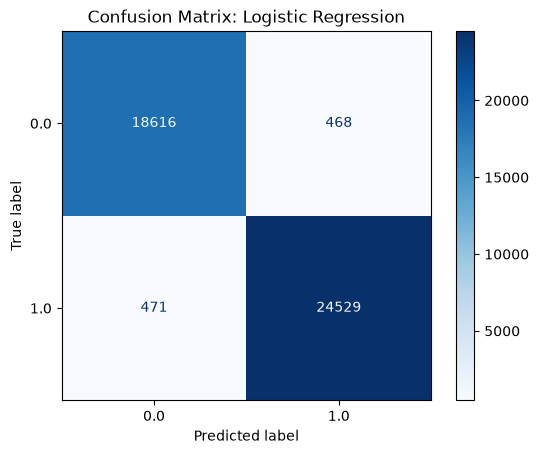

Processing: Decision Tree...
	Model: Decision Tree
	Accuracy: 0.9997731603302785
	Precision: 0.9997200447928332
	Recall: 0.99988
	F1 Score: 0.9998000159987201
	Training Time (s): 0.5583400726318359
	Prediction Time (s): 0.0029990673065185547


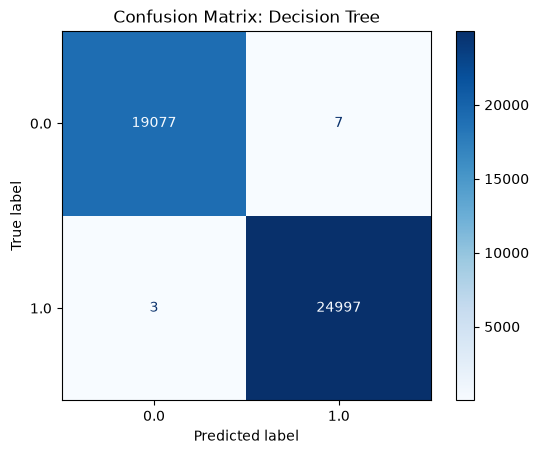

Processing: kNN...
	Model: kNN
	Accuracy: 0.9879548135377915
	Precision: 0.9937048545256446
	Recall: 0.985
	F1 Score: 0.9893332797653723
	Training Time (s): 1.1979725360870361
	Prediction Time (s): 28.174914598464966


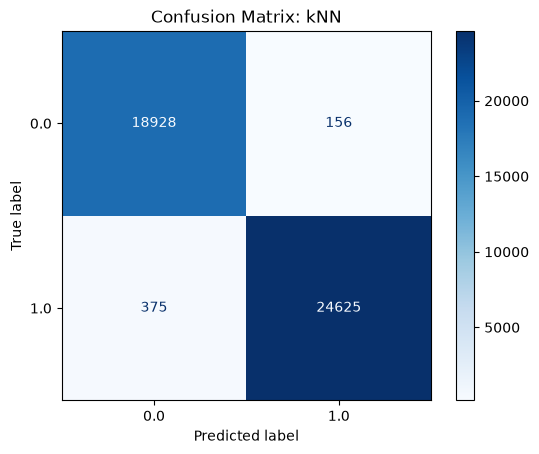

Processing: Random Forest...
	Model: Random Forest
	Accuracy: 0.9997731603302785
	Precision: 0.9997600191984641
	Recall: 0.99984
	F1 Score: 0.99980000799968
	Training Time (s): 18.659655332565308
	Prediction Time (s): 0.16121506690979004


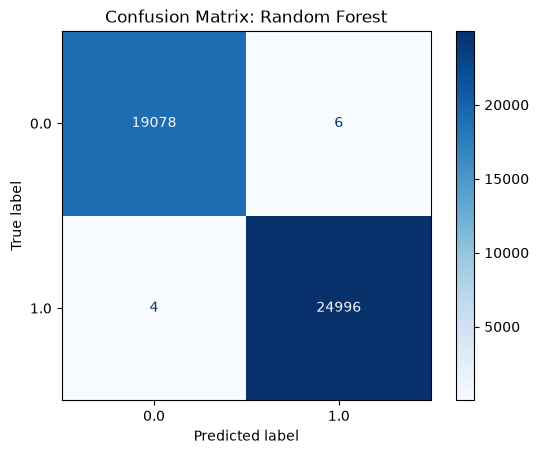

Processing: SVM...
	Model: SVM
	Accuracy: 0.9931494419744125
	Precision: 0.9921488920771561
	Recall: 0.9958
	F1 Score: 0.993971093188533
	Training Time (s): 269.09835267066956
	Prediction Time (s): 27.305681943893433


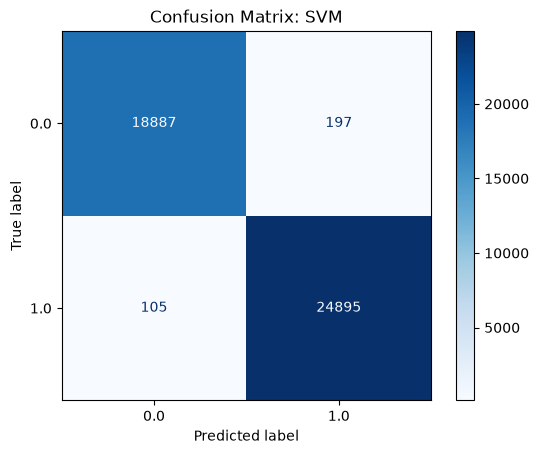

In [ ]:
# Huấn luyện từng mô hình, đo thời gian, tính các chỉ số, thu thập ROC và vẽ ma trận nhầm lẫn.

import time
# Initialize lists to store ROC data
roc_data = {}

# Train, evaluate, and collect ROC curve data
timed_results = []

for model_name, model in models.items():
    print(f'Processing: {model_name}...')
    
    # Measure training time
    start_time = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - start_time

    # Measure prediction time
    start_time = time.time()
    y_pred = model.predict(X_test_scaled)
    predict_time = time.time() - start_time
    
    # Get probabilities for ROC curve if available
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test_scaled)
    else:
        y_prob = None
    
    # Evaluate metrics
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "Training Time (s)": train_time,
        "Prediction Time (s)": predict_time
    }
    for key, value in metrics.items():
        print(f'\t{key}: {value}')
    timed_results.append(metrics)
    print('==============================')
    
    # Collect ROC curve data
    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc = auc(fpr, tpr)
        roc_data[model_name] = (fpr, tpr, roc_auc)
    
    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_ if hasattr(model, "classes_") else [0, 1])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix: {model_name}")
    plt.show()

# Convert results to DataFrame
timed_results_df = pd.DataFrame(timed_results)

In [ ]:
# Hiển thị bảng tổng hợp kết quả đánh giá các mô hình.

timed_results_df

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.978700,0.981278,0.98116,0.981219,0.324653,0.002003
1,Decision Tree,0.999773,0.999720,0.99988,0.999800,0.558340,0.002999
2,kNN,0.987955,0.993705,0.98500,0.989333,1.197973,28.174915
3,Random Forest,0.999773,0.999760,0.99984,0.999800,18.659655,0.161215
4,SVM,0.993149,0.992149,0.99580,0.993971,269.098353,27.305682


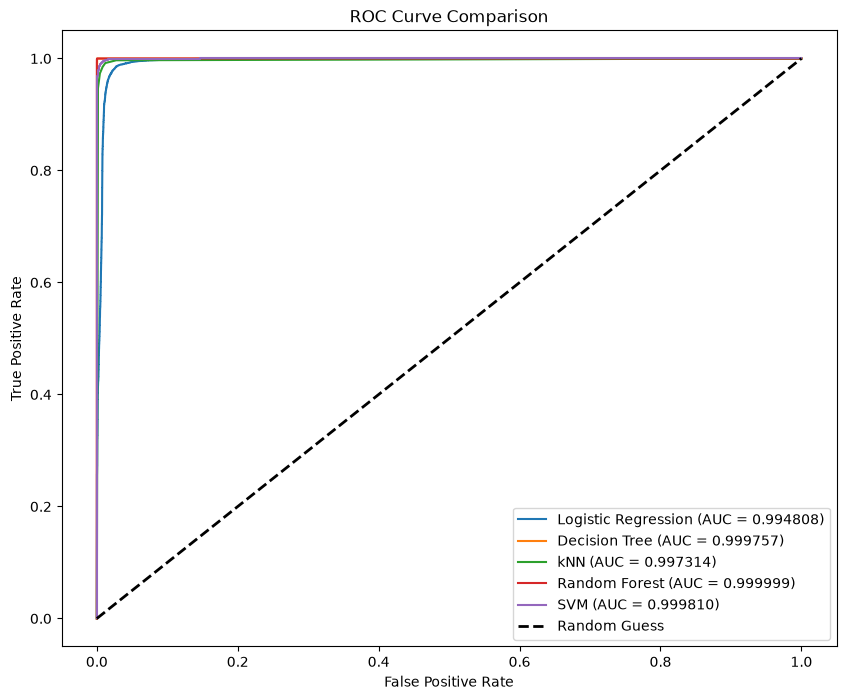

In [ ]:
# Vẽ các đường ROC để so sánh khả năng phân biệt hai lớp của các mô hình.

# Plot ROC curves for all models
plt.figure(figsize=(10, 8))
for model_name, roc_values in roc_data.items():
    fpr, tpr, roc_auc = roc_values
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc:.6f})")
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess')
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

In [ ]:
# Nạp công cụ tiền xử lý và mô hình, rồi đọc lại dữ liệu để phân tích hồi quy và cây quyết định.

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import statsmodels.api as sm

# 1. Đoc du lieu mac đinh cho cac mo hinh thong ke
dataset = pd.read_csv('customer_churn_dataset-training-master1.csv')




# 2. Lam sach du lieu khuyet thieu
dataset = dataset.dropna()

# 3. Phan loai bien
target_col = 'Churn'
drop_cols = ['CustomerID', target_col]

X = dataset.drop(columns=drop_cols)
y = dataset[target_col]

# Xac đinh danh sach cot đinh so va cot đinh tinh
num_cols = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

print(f"Cột định lượng (Numerical): {num_cols}")
print(f"Cột định tính (Categorical): {cat_cols}")

# 4. Chia tap Train/Test (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Cột định lượng (Numerical): ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Cột định tính (Categorical): ['Gender', 'Subscription Type', 'Contract Length']


In [ ]:
# Mã hóa one-hot và chuẩn hóa đặc trưng, huấn luyện Logistic Regression, xem hệ số/odds ratio và đánh giá.

# --- 1. Tao Tien xu ly cho Logistic Regression (OneHotEncoding + Chuan hoa StandardScaler) ---
preprocessor_logreg = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# Bien đoi du lieu
X_train_logreg = preprocessor_logreg.fit_transform(X_train)
X_test_logreg = preprocessor_logreg.transform(X_test)

# Lay ten cot sau khi One-Hot Encoding
encoded_cat_names = preprocessor_logreg.named_transformers_['cat'].get_feature_names_out(cat_cols)
feature_names = num_cols + list(encoded_cat_names)

# --- 2. Huan luyen Logistic Regression ---
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_logreg, y_train)

# --- 3. Trich xuat He so Beta va Odds Ratio (Dung giai thich trong nghien cuu) ---
coefficients = log_reg.coef_[0]
odds_ratios = np.exp(coefficients)

df_interpret = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient (Beta)': coefficients,
    'Odds Ratio (e^Beta)': odds_ratios
}).sort_values(by='Odds Ratio (e^Beta)', ascending=False)

print("="*60)
print("BẢNG GIẢI THÍCH TÁC ĐỘNG CỦA CÁC YẾU TỐ (LOGISTIC REGRESSION)")
print("="*60)
print(df_interpret.to_string(index=False))

# --- 4. Đanh gia mo hinh Logistic Regression ---
y_pred_logreg = log_reg.predict(X_test_logreg)
y_proba_logreg = log_reg.predict_proba(X_test_logreg)[:, 1]

print("\n--- BÁO CÁO HIỆU NĂNG LOGISTIC REGRESSION ---")
print(classification_report(y_test, y_pred_logreg))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_logreg):.4f}")

BẢNG GIẢI THÍCH TÁC ĐỘNG CỦA CÁC YẾU TỐ (LOGISTIC REGRESSION)
                   Feature  Coefficient (Beta)  Odds Ratio (e^Beta)
   Contract Length_Monthly           10.078748         23831.134383
             Support Calls            2.302557             9.999720
             Payment Delay            0.924675             2.521050
          Last Interaction            0.525300             1.690967
                       Age            0.445015             1.560513
 Contract Length_Quarterly           -0.012644             0.987436
Subscription Type_Standard           -0.121476             0.885612
 Subscription Type_Premium           -0.122300             0.884883
           Usage Frequency           -0.128431             0.879474
                    Tenure           -0.136103             0.872752
               Gender_Male           -1.149001             0.316953
               Total Spend           -1.456512             0.233048

--- BÁO CÁO HIỆU NĂNG LOGISTIC REGRESSION ---
       

In [ ]:
# Huấn luyện mô hình Logit của statsmodels và in hệ số cùng các kiểm định ý nghĩa thống kê.

# Them cot Intercept cho statsmodels
X_train_sm = sm.add_constant(X_train_logreg)

# Chay mo hinh Logit cua statsmodels
logit_model = sm.Logit(y_train.values, X_train_sm)
result = logit_model.fit(disp=False)

# In tom tat thong ke (Bao gom p-value & Khoang tin cay 95%)
summary_df = pd.DataFrame({
    'Feature': ['Intercept'] + feature_names,
    'Coef': result.params,
    'Std Err': result.bse,
    'z-score': result.tvalues,
    'P-value (P>|z|)': result.pvalues,
    'Odds Ratio': np.exp(result.params)
})

print("="*60)
print("BẢNG KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ (STATSMODELS LOGIT)")
print("="*60)
print(summary_df.to_string(index=False))

BẢNG KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ (STATSMODELS LOGIT)
                   Feature      Coef    Std Err     z-score  P-value (P>|z|)   Odds Ratio
                 Intercept  1.360638   0.015590   87.275058     0.000000e+00 3.898678e+00
                       Age  0.445359   0.006902   64.528231     0.000000e+00 1.561051e+00
                    Tenure -0.136282   0.006163  -22.111316    2.459900e-108 8.725964e-01
           Usage Frequency -0.128888   0.006167  -20.898254     5.553974e-97 8.790724e-01
             Support Calls  2.303758   0.010574  217.864395     0.000000e+00 1.001174e+01
             Payment Delay  0.925618   0.007213  128.332578     0.000000e+00 2.523428e+00
               Total Spend -1.457874   0.008264 -176.410097     0.000000e+00 2.327304e-01
          Last Interaction  0.525368   0.006601   79.584638     0.000000e+00 1.691081e+00
               Gender_Male -1.150539   0.013241  -86.891521     0.000000e+00 3.164661e-01
 Subscription Type_Premium -0.121365   0.015083 

c:\Users\ASUS\.conda\envs\DA\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(



--- BÁO CÁO HIỆU NĂNG DECISION TREE ---
              precision    recall  f1-score   support

         0.0       0.85      0.99      0.92     38167
         1.0       0.99      0.87      0.93     50000

    accuracy                           0.92     88167
   macro avg       0.92      0.93      0.92     88167
weighted avg       0.93      0.92      0.92     88167

ROC-AUC Score: 0.9328


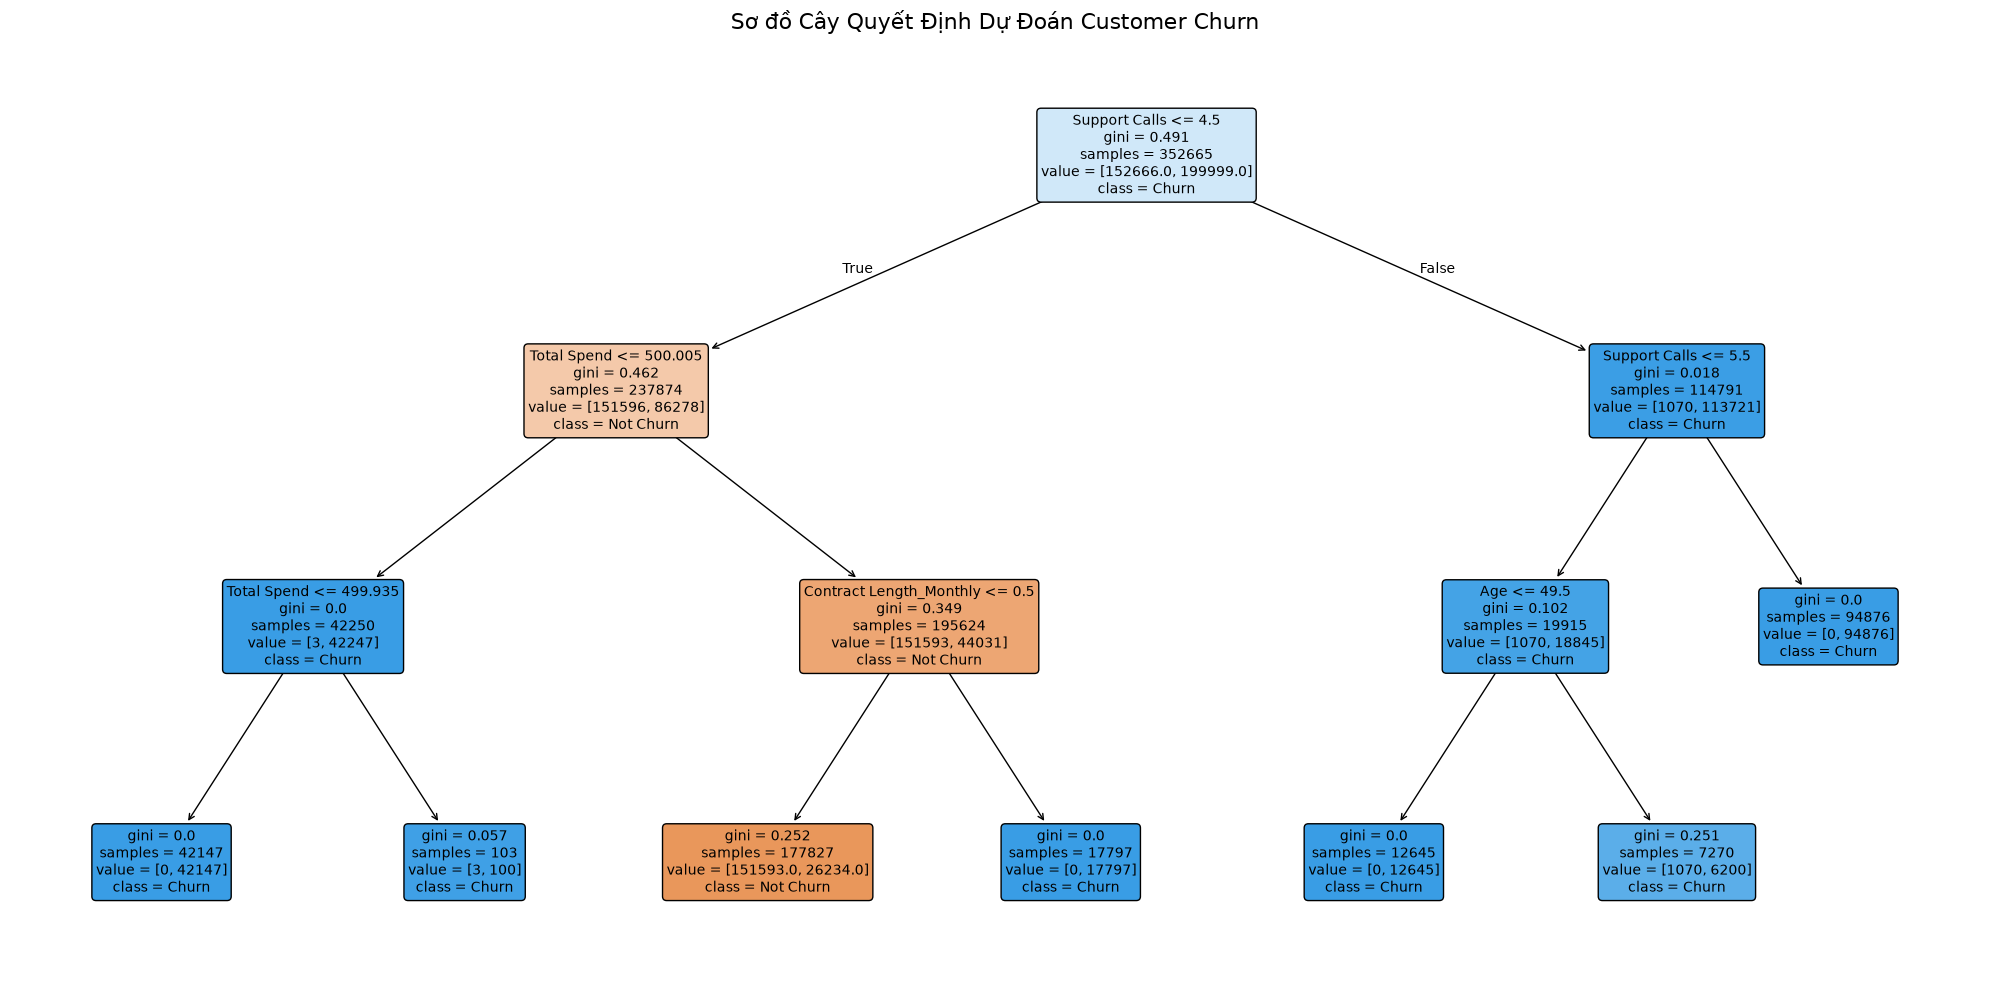


--- BỘ QUY TẮC QUYẾT ĐỊNH (IF-THEN RULES) ---
|--- Support Calls <= 4.50
|   |--- Total Spend <= 500.01
|   |   |--- Total Spend <= 499.93
|   |   |   |--- class: 1.0
|   |   |--- Total Spend >  499.93
|   |   |   |--- class: 1.0
|   |--- Total Spend >  500.01
|   |   |--- Contract Length_Monthly <= 0.50
|   |   |   |--- class: 0.0
|   |   |--- Contract Length_Monthly >  0.50
|   |   |   |--- class: 1.0
|--- Support Calls >  4.50
|   |--- Support Calls <= 5.50
|   |   |--- Age <= 49.50
|   |   |   |--- class: 1.0
|   |   |--- Age >  49.50
|   |   |   |--- class: 1.0
|   |--- Support Calls >  5.50
|   |   |--- class: 1.0



In [ ]:
# Tiền xử lý dữ liệu, huấn luyện và đánh giá cây quyết định; hiển thị cây và luật phân nhánh.

# --- 1. Tien xu ly rieng cho Cay quyet đinh (Giu nguyen ti le bien so) ---
preprocessor_dt = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

X_train_dt = preprocessor_dt.fit_transform(X_train)
X_test_dt = preprocessor_dt.transform(X_test)

# --- 2. Huan luyen Decision Tree (Gioi han max_depth=3 hoac 4 đe de đoc cay) ---
tree_model = DecisionTreeClassifier(
    max_depth=3,            # Giới hạn độ sâu để mô hình không bị phức tạp
    criterion='gini',
    min_samples_leaf=100,  # Tránh phân nhánh rác
    random_state=42
)
tree_model.fit(X_train_dt, y_train)

# --- 3. Đanh gia Decision Tree ---
y_pred_tree = tree_model.predict(X_test_dt)
y_proba_tree = tree_model.predict_proba(X_test_dt)[:, 1]

print("\n--- BÁO CÁO HIỆU NĂNG DECISION TREE ---")
print(classification_report(y_test, y_pred_tree))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_tree):.4f}")

# --- 4. Truc quan hoa Cay quyet đinh ---
plt.figure(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=['Not Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Sơ đồ Cây Quyết Định Dự Đoán Customer Churn", fontsize=16)
plt.tight_layout()
plt.show()

# --- 5. In luat quyet đinh (If-Then Rules) dang Text ---
print("\n--- BỘ QUY TẮC QUYẾT ĐỊNH (IF-THEN RULES) ---")
tree_rules = export_text(tree_model, feature_names=feature_names)
print(tree_rules)

## 4. Mạng neural network học sâu

In [ ]:
# Nạp các thành phần Keras cần thiết để xây dựng và đánh giá mạng nơ-ron.

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import Precision, Recall

In [ ]:
# Xây dựng mạng nơ-ron nhiều lớp ẩn với ReLU, Dropout và đầu ra sigmoid cho phân loại nhị phân.

model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')  # Output layer with sigmoid for binary classification
])

c:\Users\ASUS\.conda\envs\DA\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# In cấu trúc mạng nơ-ron, gồm các lớp và số tham số của từng lớp.

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Cấu hình cách tối ưu trọng số, hàm mất mát nhị phân và các chỉ số theo dõi.

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=[
                    'accuracy', 
                    Precision(), 
                    Recall()
                    ]
             )

In [ ]:
# Huấn luyện mạng nơ-ron, dành một phần dữ liệu train để kiểm định và đo thời gian chạy.

# Train
start_time = time.time()
history = model.fit(X_train_scaled, y_train, validation_split=0.2, epochs=5, batch_size=32, verbose=1)
train_time = time.time() - start_time

Epoch 1/5
9886/9919 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5661 - loss: 0.6848 - precision: 0.5669 - recall: 0.9950

ValueError: Data cardinality is ambiguous. Make sure all arrays contain the same number of samples.'x' sizes: 79350
'y' sizes: 35267


In [ ]:
# Dự đoán xác suất trên tập test, đo thời gian dự đoán và chuyển xác suất thành nhãn theo ngưỡng 0,5.

# Test
start_time = time.time()
y_pred_prob_nn = model.predict(X_test_scaled)
predict_time = time.time() - start_time

# Process predictions for evaluation
y_pred_nn = (y_pred_prob_nn > 0.5).astype(int)

1378/1378 ━━━━━━━━━━━━━━━━━━━━ 1s 957us/step


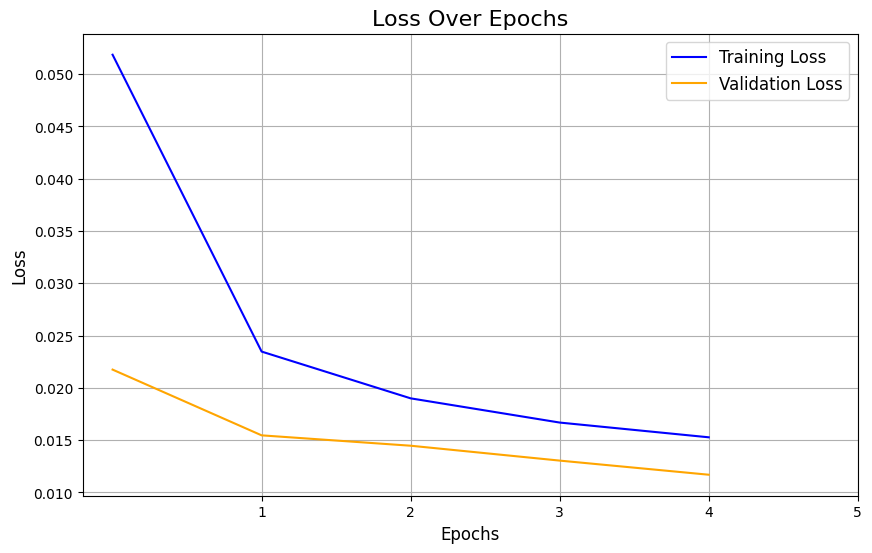

In [ ]:
# Vẽ loss của tập huấn luyện và kiểm định qua từng epoch để quan sát quá trình học.

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title("Loss Over Epochs", fontsize=16)
plt.xlabel("Epochs", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.xticks([1,2,3,4,5])
plt.legend(fontsize=12)
plt.grid(True)
plt.show()

In [ ]:
# Tính các chỉ số đánh giá mạng nơ-ron, thêm kết quả vào danh sách và cập nhật bảng so sánh.

# Evaluate metrics for Neural Network
metrics_nn = {
    "Model": "Neural Network",
    "Accuracy": accuracy_score(y_test, y_pred_nn),
    "Precision": precision_score(y_test, y_pred_nn),
    "Recall": recall_score(y_test, y_pred_nn),
    "F1 Score": f1_score(y_test, y_pred_nn),
    "Training Time (s)": train_time,
    "Prediction Time (s)": predict_time
}
print(metrics_nn)
timed_results.append(metrics_nn)

# Convert updated results to DataFrame
updated_timed_results_df = pd.DataFrame(timed_results)

updated_timed_results_df

{'Model': 'Neural Network', 'Accuracy': 0.9946692677615462, 'Precision': 0.9928750547307248, 'Recall': 0.99776, 'F1 Score': 0.9953115336272769, 'Training Time (s)': 85.5774257183075, 'Prediction Time (s)': 1.9501912593841553}


,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.978586,0.981197,0.98104,0.981118,0.810583,0.001365
1,Decision Tree,0.999819,0.999720,0.99996,0.999840,0.874901,0.003193
2,kNN,0.987955,0.993705,0.98500,0.989333,1.227853,36.450838
3,Random Forest,0.999796,0.999720,0.99992,0.999820,29.831827,0.289822
4,SVM,0.993127,0.992109,0.99580,0.993951,329.318872,24.801024
5,Neural Network,0.994669,0.992875,0.99776,0.995312,85.577426,1.950191


1. Đánh giá từng chỉ số

- Độ chính xác (Accuracy):
    - Decision Tree (99.9864%) và Random Forest (99.9819%) đạt độ chính xác rất cao, gần như hoàn hảo.
    - Neural Network cũng đạt độ chính xác tốt (99.7187%).
    - Các mô hình còn lại có độ chính xác thấp hơn, nhưng Logistic Regression (97.8586%) và SVM (99.3127%) vẫn rất tốt.

- Độ chính xác dự đoán đúng lớp (Precision):
    - Decision Tree và Random Forest đạt precision rất cao, gần như hoàn hảo.
    - Neural Network (99.6805%) và kNN (99.3705%) cũng có precision tốt.
    - Logistic Regression (98.1197%) là thấp nhất trong số các mô hình.

- Tỷ lệ phát hiện đúng lớp (Recall):
    - Decision Tree (99.996%) và Random Forest (99.996%) gần như hoàn hảo.
    - Neural Network đạt recall cao (99.824%), vượt qua hầu hết các mô hình còn lại.
    - Logistic Regression (98.104%) và kNN (98.500%) thấp hơn một chút.

- F1 Score:
    - Decision Tree (99.988%) và Random Forest (99.984%) vẫn dẫn đầu.
    - Neural Network có F1 Score gần kề với (99.7522%).
    - SVM cũng đạt F1 tốt (99.3951%), vượt qua Logistic Regression và kNN.

- Thời gian huấn luyện (Training Time):
    - Decision Tree nhanh nhất (0.726s).
    - Logistic Regression và kNN cũng nhanh (1.1s).
    - SVM (243.6s) và Neural Network (98.6s) tốn thời gian đáng kể.
    - Random Forest mất 22.4s, hợp lý với độ chính xác cao.

- Thời gian dự đoán (Prediction Time):
    - Logistic Regression và Decision Tree nhanh nhất (0.001-0.003s).
    - kNN (31.68s) tốn thời gian lớn nhất do phải tính toán khoảng cách.
    - SVM (19.02s) và Neural Network (2.46s) cũng cần cải thiện.

2. Tổng kết: Lựa chọn mô hình
- Dựa vào độ chính xác và hiệu suất (Best Overall): Decision Tree và Random Forest là lựa chọn hàng đầu với hiệu suất gần như hoàn hảo, thời gian huấn luyện và dự đoán hợp lý (Accuracy, Precision, Recall, F1-score)
- Với thời gian hạn chế (Low Latency): Logistic Regression phù hợp với các bài toán yêu cầu tốc độ cao và tài nguyên hạn chế (Tổng Training time + Prediction time nhanh nhất)
- Đối với dữ liệu phức tạp và lớn: Neural Network có thể xử lý tốt hơn trong các bài toán phức tạp hơn.

## 5. So sanh 5 mo hinh tren 3 bo du lieu

`dataset.csv` la ban sao byte-for-byte cua `customer_churn_dataset-testing-master2.csv`, nen khong duoc dung lam bo thu ba. Thi nghiem duoi day dung them `customer_churn.csv` (Telco Customer Churn), tu dong chuan hoa cot dich va tien xu ly rieng cho tung bo du lieu. Ket qua gom 15 dong (3 bo du lieu x 5 mo hinh).


In [ ]:
# So sánh năm mô hình trên ba bộ dữ liệu; tiền xử lý theo kiểu cột, giới hạn mẫu và ghi lại hiệu năng/thời gian.

# Comparative experiment: 3 datasets x 5 models
import time
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

MAX_ROWS_PER_DATASET = 10000

# Khai báo tên từng bộ dữ liệu và đường dẫn tới tệp CSV tương ứng.
DATASETS = {
    "Training master 1": "customer_churn_dataset-training-master1.csv",
    "Testing master 2": "customer_churn_dataset-testing-master2.csv",
    "Telco churn": "customer_churn.csv",
}


# Định nghĩa hàm đọc dữ liệu và xử lý khác biệt về tên cột/nhãn giữa các bộ dữ liệu.
def load_dataset(name, filename):
    # Đọc tệp CSV vào DataFrame để bắt đầu chuẩn hóa dữ liệu.
    data = pd.read_csv(filename)
    if name == "Telco churn":
        data["TotalCharges"] = pd.to_numeric(data["TotalCharges"], errors="coerce")
        y = data["Churn"].map({"Yes": 1, "No": 0})
        X = data.drop(columns=["customerID", "Churn"])
    else:
        y = pd.to_numeric(data["Churn"], errors="coerce")
        X = data.drop(columns=["CustomerID", "Churn"])

    valid = y.notna()
    X = X.loc[valid].reset_index(drop=True)
    y = y.loc[valid].astype(int).reset_index(drop=True)
    # Giới hạn số mẫu để thí nghiệm chạy nhanh, đồng thời giữ tỷ lệ lớp bằng chia có phân tầng.
    if len(X) > MAX_ROWS_PER_DATASET:
        X, _, y, _ = train_test_split(
            X, y, train_size=MAX_ROWS_PER_DATASET, random_state=42, stratify=y
        )
    return X.reset_index(drop=True), y.reset_index(drop=True)


# Khởi tạo các mô hình sẽ được đánh giá trên từng bộ dữ liệu.
MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    # LinearSVC is an SVM and is scalable for the 440k-row training dataset.
    "SVM": LinearSVC(random_state=42, max_iter=5000),
}

# Lưu kết quả của từng cặp bộ dữ liệu và mô hình vào danh sách này.
results = []
# Lặp qua từng bộ dữ liệu, sau đó chia thành tập huấn luyện và tập kiểm tra.
for dataset_name, filename in DATASETS.items():
    X, y = load_dataset(dataset_name, filename)
    X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Tách tên các cột số và cột phân loại để áp dụng cách tiền xử lý phù hợp.
    numeric_cols = X_train_exp.select_dtypes(include="number").columns.tolist()
    categorical_cols = X_train_exp.select_dtypes(exclude="number").columns.tolist()
    # Điền giá trị thiếu, chuẩn hóa cột số và one-hot encode cột phân loại trong một pipeline.
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]),
                numeric_cols,
            ),
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]),
                categorical_cols,
            ),
        ]
    )

    # Tạo pipeline gồm bước tiền xử lý và mô hình đang được đánh giá.
    for model_name, estimator in MODELS.items():
        pipeline = Pipeline([
            ("preprocess", preprocessor),
            ("model", estimator),
        ])
        start = time.perf_counter()
        # Huấn luyện pipeline và đo thời gian hoàn tất quá trình fit.
        pipeline.fit(X_train_exp, y_train_exp)
        train_time = time.perf_counter() - start
        start = time.perf_counter()
        # Dự đoán nhãn của tập test và đo thời gian dự đoán.
        predictions = pipeline.predict(X_test_exp)
        prediction_time = time.perf_counter() - start

        # Ghi kích thước dữ liệu, các chỉ số phân loại và thời gian vào kết quả thí nghiệm.
        results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Rows": len(X),
            "Accuracy": accuracy_score(y_test_exp, predictions),
            "Precision": precision_score(y_test_exp, predictions, zero_division=0),
            "Recall": recall_score(y_test_exp, predictions, zero_division=0),
            "F1 Score": f1_score(y_test_exp, predictions, zero_division=0),
            "Training Time (s)": train_time,
            "Prediction Time (s)": prediction_time,
        })

# Chuyển kết quả thành DataFrame để hiển thị và so sánh thuận tiện.
results_df = pd.DataFrame(results)
print(f"So ket qua: {len(results_df)} (3 datasets x 5 models)")
display(results_df.round(4))


So ket qua: 15 (3 datasets x 5 models)


,Dataset,Model,Rows,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,Training master 1,Logistic Regression,10000,0.9060,0.9429,0.8880,0.9146,0.0437,0.0066
1,Training master 1,Decision Tree,10000,0.9975,0.9991,0.9965,0.9978,0.0369,0.0077
2,Training master 1,kNN,10000,0.9125,0.9908,0.8536,0.9171,0.0405,0.1586
3,Training master 1,Random Forest,10000,0.9900,0.9982,0.9841,0.9911,0.1783,0.0326
4,Training master 1,SVM,10000,0.9065,0.9454,0.8862,0.9149,0.0295,0.0063
5,Testing master 2,Logistic Regression,10000,0.8390,0.8438,0.8099,0.8265,0.0239,0.0056
6,Testing master 2,Decision Tree,10000,0.9900,0.9905,0.9884,0.9894,0.0288,0.0071
7,Testing master 2,kNN,10000,0.8780,0.8540,0.8955,0.8742,0.0378,0.1607
8,Testing master 2,Random Forest,10000,0.9885,0.9968,0.9789,0.9877,0.1743,0.0313
9,Testing master 2,SVM,10000,0.8380,0.8397,0.8131,0.8262,0.0213,0.0054
